# Создание нейронной сети на Torch

In [ ]:
import torch
import numpy as np

## Нейрон

<img src="img/neuron.png" width=300, heigth=300>

In [ ]:
# Создание класса нейрон. weights - веса связей, bias - порог, input - вектор сигналов, подающихся на нейрон

class Neuron:
  def __init__(self, weights, bias):
    self.weights = weights
    self.bias = bias

  def forward(self, input):
    return torch.dot(self.weights, input) + self.bias # dot - скалярное произведение векторов

In [ ]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])

weights = torch.tensor([0.2, 0.8, -0.5, 1.0])
bias = 2.0

neuron = Neuron(weights, bias)
neuron.forward(inputs)

tensor(4.8000)

## Слой

<img src="img/Layer.png" width=300, heigth=300>

In [ ]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases

  def forward(self, input):
    return torch.mv(self.weights, input) + self.biases #mv - произведение вектора на матрицу

In [ ]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])
weights = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])

biases = torch.tensor([2.0, 3.0, 0.5])

layer = Layer(weights, biases)
layer.forward(inputs)

tensor([4.8000, 1.2100, 2.3850])

## Слой (batch)
обработка партиями

In [ ]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases

  def forward(self, inputs):
    return inputs @ self.weights.T + self.biases # провизведение матриц

In [ ]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
weights1 = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])
biases1 = torch.tensor([2.0, 3.0, 0.5])

weights2 = torch.tensor([[.1, -.14, .5], [-.5, .12, -.33], [-.44, .73, -.13]])
biases2 = torch.tensor([-1, 2, -.5])

layer1 = Layer(weights1, biases1)
hidden_input = layer1.forward(inputs1)

layer2 = Layer(weights2, biases2)
output = layer2.forward(hidden_input)
output

tensor([[ 0.5031, -1.0419, -2.0388],
        [ 0.2434, -2.7332, -5.7633],
        [-0.9931,  1.4125, -0.3565]])

## Слой (случ. иниц)

In [ ]:
class Layer:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons)
    self.biases = torch.zeros(n_neurons)

  def forward(self, inputs):
    return inputs @ self.weights + self.biases

In [ ]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 6)
out = layer.forward(inputs1)
out

tensor([[ 6.0564, -2.0423, -2.9318,  4.2614,  5.9039,  1.1787],
        [ 0.1285,  9.2146, -3.8348,  5.8550,  5.9263, -7.8385],
        [ 2.8381,  1.1598, -1.3808,  5.0770,  4.5775, -3.3245]])

## Функции активации

<img src="img/Act.png" width=500, heigth=300>

Функция активации ReLU:
![](https://wikimedia.org/api/rest_v1/media/math/render/svg/f4353f4e3e484130504049599d2e7b040793e1eb)
Функцию активации softmax:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/6d7500d980c313da83e4117da701bf7c8f1982f5)

In [ ]:
# RELU
class ReLU:
  def forward(self, inputs):
    return inputs.clip(min=0)    # заменить отрицательные числа нулями

In [ ]:
ReLU().forward(out)

tensor([[6.0564, 0.0000, 0.0000, 4.2614, 5.9039, 1.1787],
        [0.1285, 9.2146, 0.0000, 5.8550, 5.9263, 0.0000],
        [2.8381, 1.1598, 0.0000, 5.0770, 4.5775, 0.0000]])

In [ ]:
class Softmax:
  def forward(self, inputs):
    exp = torch.exp(inputs)
    probs = exp / exp.sum(dim=1, keepdim=True)
    return probs

In [ ]:
Softmax().forward(out)

tensor([[4.9195e-01, 1.4952e-04, 6.1431e-05, 8.1722e-02, 4.2237e-01, 3.7459e-03],
        [1.0561e-04, 9.3268e-01, 2.0066e-06, 3.2411e-02, 3.4803e-02, 3.6614e-08],
        [6.1424e-02, 1.1467e-02, 9.0385e-04, 5.7634e-01, 3.4974e-01, 1.2941e-04]])

## Функции потерь

Функция потерь MSE:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/e258221518869aa1c6561bb75b99476c4734108e)
Функция потерь Categorical Cross-Entropy:

<img src="https://i.ibb.co/93gy1dN/Screenshot-9.png" width="200">


In [ ]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 1)
out = layer.forward(inputs1)
out

tensor([[-0.7693],
        [ 6.1080],
        [ 2.8369]])

In [ ]:
# Среднеквадратичная ошибка
class MSELoss:
  def forward(self, y_pred, y_true):
    return torch.mean(torch.pow(out - y_true, 2))

In [ ]:
y_true = torch.tensor([2, 3, 4]).view(-1, 1)
MSELoss().forward(out, y_true)

tensor(6.2271)

In [ ]:
# Кроссэнтропия
class CategoricalCrossentropyLoss:
  def forward(self, y_pred, y_true):
    correct_conf = y_pred.gather(dim=1, index=y_true.view(-1, 1))
    neglog = -torch.log(correct_conf)
    return torch.mean(neglog)

In [ ]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 3)
out = layer.forward(inputs1)
out = Softmax().forward(out)
out

tensor([[0.8235, 0.0939, 0.0826],
        [0.3234, 0.6734, 0.0032],
        [0.9887, 0.0010, 0.0103]])

In [ ]:
y_true = torch.tensor([1, 0, 0])
CategoricalCrossentropyLoss().forward(out, y_true)

tensor(1.1686)

## Оптимизация SGD (стохастический градиентный спуск)

#### Модифицируем класс Neuron
    Сделаем так, чтобы веса нейрона инициализировались из стандартного нормального распределения:

In [ ]:
# Сформируем случайную задачу регркессии
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

Граф вычислений для решения задачи:
<img src="img/back.png" width=700, heigth=700>

In [ ]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs)
    self.bias = torch.randn(1)

  def forward(self, input):
    self.input = input
    return torch.dot(self.weights, input) + self.bias

  def backward(self, dvalue):
    self.dweights = dvalue * self.input
    self.dinput = dvalue * self.weights
    self.dbias = dvalue


class Loss:    #класс вычисления ошибок
  def forward(self, y_pred, y_true):
    return (y_pred - y_true) ** 2

  def backward(self, y_pred, y_true):
    self.dinput = 2 * (y_pred - y_true)


In [ ]:
neuron = Neuron(4)
loss = Loss()

lr = 0.1

losses = []
for epoch in range(100):
  for x_example, y_example in zip(X, y):
    y_pred = neuron.forward(x_example)
    l = loss.forward(y_pred, y_example)
    losses.append(l)

    loss.backward(y_pred, y_example)
    neuron.backward(loss.dinput)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbias


In [ ]:
neuron.weights, neuron.bias

(tensor([ 2.0915, 28.2249, 75.2287,  1.7709]), tensor([0.5000]))

#### Используем пакетный градиентный спуск (batch SGD + neuron)

In [ ]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs, requires_grad=False)
    self.bias = torch.tensor(0.0, requires_grad=False)

  def forward(self, inputs):
    self.inputs = inputs
    return X @ self.weights.T + self.bias

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T.mv(dvalues)
      self.dbiases = dvalues.sum()


class MSELossNeuron:
  def forward(self, y_pred, y_true):
    return torch.mean((y_pred - y_true) ** 2)

  def backward(self, y_pred, y_true):
    with torch.no_grad():
      self.dinputs = 2 * (y_pred - y_true) / len(y_pred)

Вычисления для решения задачи:
    <img src="img/back1.png" width=700, heigth=700>
    <img src="img/back2.png" width=700, heigth=700>

In [ ]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

In [ ]:
neuron = Neuron(4)
loss = MSELossNeuron()

lr = 0.1

for epoch in range(100):
    y_pred = neuron.forward(X)
    l = loss.forward(y_pred, y)
    loss.backward(y_pred, y)
    neuron.backward(loss.dinputs)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbiases
print(f'epoch {epoch} mean loss {l.mean()}')

epoch 99 mean loss 4.556700616831222e-08


/tmp/ipykernel_367/2213006203.py:8: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  return X @ self.weights.T + self.bias


In [ ]:
neuron.weights, coef

(tensor([90.7238, 88.3971, 12.1017, 95.2754]),
 array([90.723814  , 88.39712864, 12.10176033, 95.27563032]))

### Разные варианты веализации рейросети

In [ ]:
class Dense:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons, requires_grad=False)
    self.biases = torch.zeros(n_neurons, requires_grad=False)

  def forward(self, inputs):
    self.inputs = inputs
    self.output = self.inputs @ self.weights + self.biases
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T @ dvalues
      self.dbiases = torch.sum(dvalues, dim=0)
      self.dinputs = dvalues @ self.weights.T

class Activation_ReLU:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs.clip(min=0)
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()
      self.dinputs[self.inputs <= 0] = 0

class Activation_Linear:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()

class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = sample_losses.mean()
    return data_loss

class MSELoss(Loss):
  def forward(self, y_pred, y_true):
    sample_losses = torch.mean((y_true - y_pred) ** 2, dim=1)
    return sample_losses

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      self.dinputs = -2 * (y_true - dvalues) / len(dvalues)


In [ ]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [ ]:
fc1 = Dense(4, 1)
loss = MSELoss()
lr = 0.1

for epoch in range(100):
  out = fc1.forward(X)
  data_loss = loss.calculate(out, y.view(-1, 1))
  print(f'epoch {epoch} mean loss {data_loss}')
  loss.backward(out, y.view(-1, 1))
  fc1.backward(loss.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

epoch 0 mean loss 6304.87109375
epoch 1 mean loss 3720.149658203125
epoch 2 mean loss 2204.0380859375
epoch 3 mean loss 1311.3582763671875
epoch 4 mean loss 783.6642456054688
epoch 5 mean loss 470.4363708496094
epoch 6 mean loss 283.7154235839844
epoch 7 mean loss 171.91680908203125
epoch 8 mean loss 104.67494201660156
epoch 9 mean loss 64.0450668334961
epoch 10 mean loss 39.379798889160156
epoch 11 mean loss 24.334789276123047
epoch 12 mean loss 15.113680839538574
epoch 13 mean loss 9.434566497802734
epoch 14 mean loss 5.919792652130127
epoch 15 mean loss 3.7338030338287354
epoch 16 mean loss 2.3674941062927246
epoch 17 mean loss 1.50923752784729
epoch 18 mean loss 0.9673846364021301
epoch 19 mean loss 0.6235426068305969
epoch 20 mean loss 0.4042111337184906
epoch 21 mean loss 0.26356613636016846
epoch 22 mean loss 0.17288997769355774
epoch 23 mean loss 0.11410608142614365
epoch 24 mean loss 0.0757804661989212
epoch 25 mean loss 0.05064854770898819
epoch 26 mean loss 0.034069426357746

In [ ]:
fc1.weights, coef

(tensor([[51.6760],
         [ 8.6621],
         [ 2.1659],
         [50.4168]]),
 array([51.67602792,  8.66212303,  2.16589378, 50.41682328]))

In [ ]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [ ]:
X = torch.linspace(-1, 1, 100).view(-1, 1)
y = X.pow(2) + 0.2 * torch.rand(X.size())

In [ ]:
fc1 = Dense(1, 10)
relu1 = Activation_ReLU()
fc2 = Dense(10, 1)

loss = MSELoss()
lr = 0.02

ys = []
for epoch in range(2001):
  out = fc1.forward(X)
  out = relu1.forward(out)
  out = fc2.forward(out)


  data_loss = loss.calculate(out, y)
  if epoch % 200 == 0:
    print(f'epoch {epoch} mean loss {data_loss}')
    ys.append(out)
  loss.backward(out, y)
  fc2.backward(loss.dinputs)
  relu1.backward(fc2.dinputs)
  fc1.backward(relu1.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

  fc2.weights -= lr * fc2.dweights
  fc2.biases -= lr * fc2.dbiases

epoch 0 mean loss 2.0560929775238037
epoch 200 mean loss 0.016503341495990753
epoch 400 mean loss 0.00966081116348505
epoch 600 mean loss 0.00676339864730835
epoch 800 mean loss 0.005845237523317337
epoch 1000 mean loss 0.005316989962011576
epoch 1200 mean loss 0.0049702441319823265
epoch 1400 mean loss 0.004690010100603104
epoch 1600 mean loss 0.004446730483323336
epoch 1800 mean loss 0.0042237527668476105
epoch 2000 mean loss 0.004091741517186165


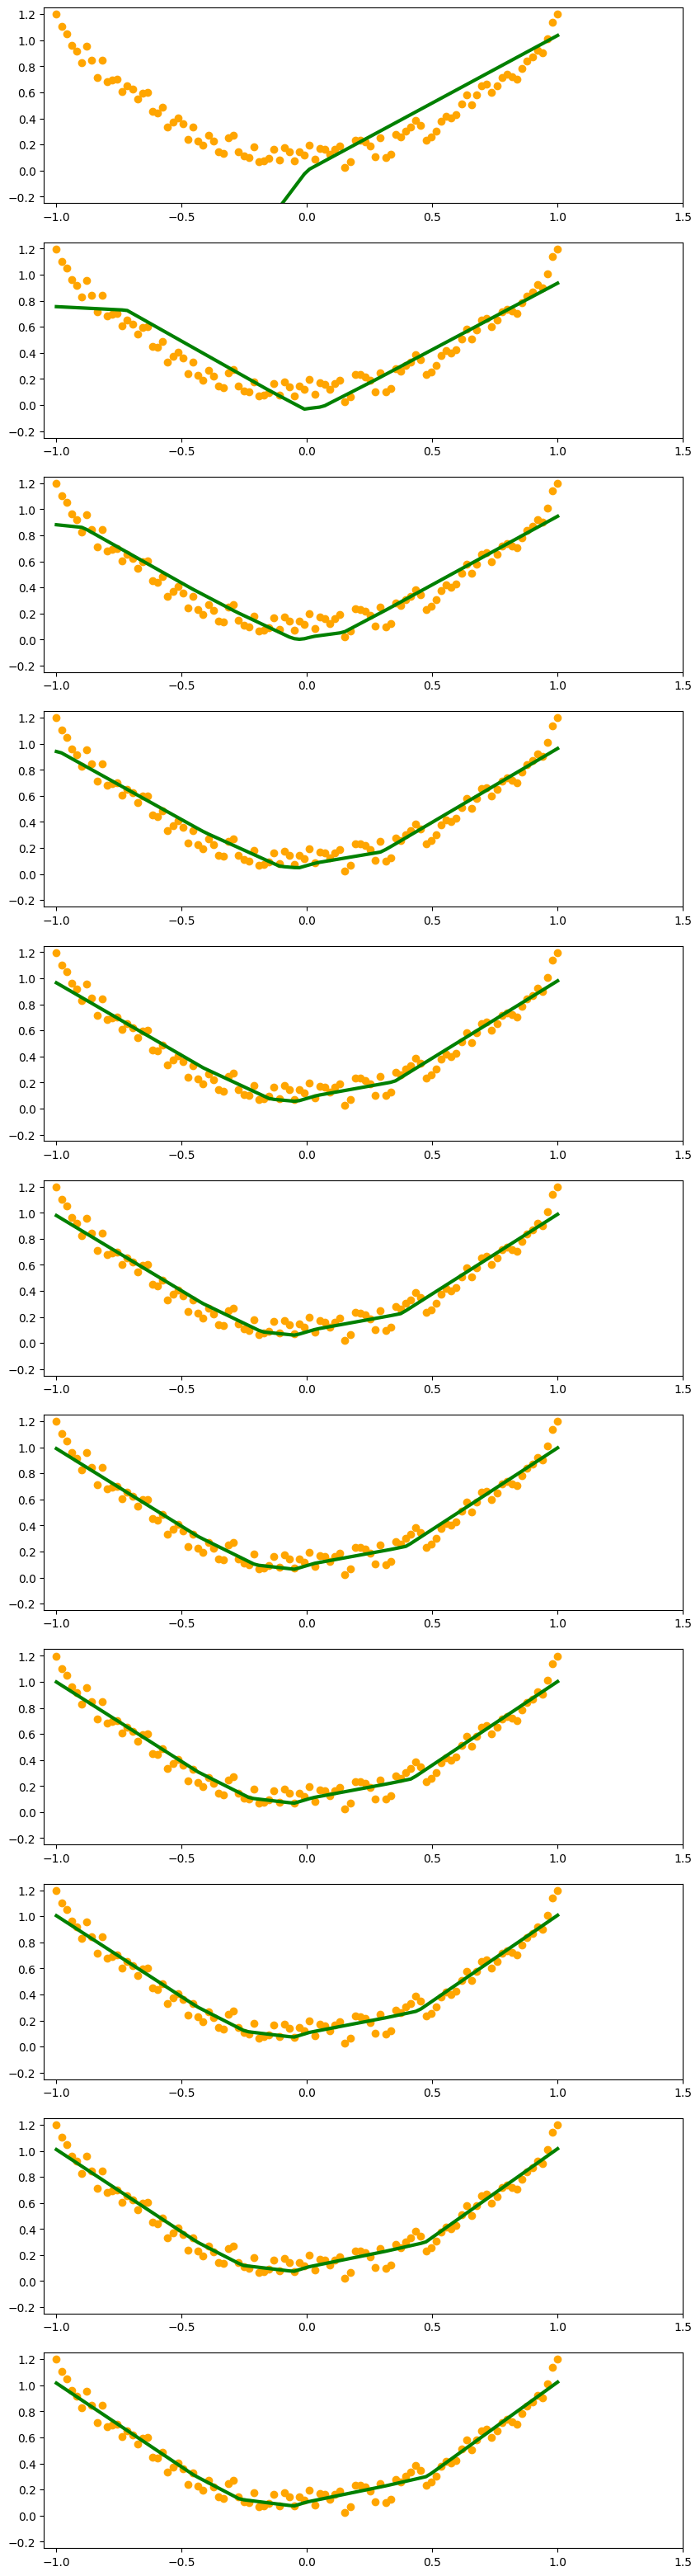

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(ys), 1, figsize=(10, 40))
for ax, y_ in zip(axs, ys):
  ax.scatter(X.numpy(), y.numpy(), color = "orange")
  ax.plot(X.numpy(), y_.numpy(), 'g-', lw=3)
  ax.set_xlim(-1.05, 1.5)
  ax.set_ylim(-0.25, 1.25)

<h1>Практическая работа: "Нейронная сеть для бинарной классификации. ROC-кривая и AUC ROC"</h1>

<h1>Задание</h1>

1. Разобраться с материалом, представленным в работе: нейрон, слой, функции активации, функции потерь, обратное распространение ошибки, стохастический градиентный спуск.
2. Создать и обучить нейронную сеть. Датасет можно взять произвольный.
3. Оценить качество модели с помощью ROC-кривой и AUC ROC. Материал по теме: статья А. Дьяконова
   [«AUC ROC (площадь под кривой ошибок)»](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/).

Для решения выбран набор данных «Breast Cancer Wisconsin» из библиотеки scikit-learn.
По 30 числовым характеристикам клеточных ядер нужно определить, является опухоль
злокачественной (`0`) или доброкачественной (`1`).

## Цель работы

Необходимо построить нейронную сеть, которая по признакам образца предсказывает
класс опухоли, и оценить, насколько хорошо она отделяет один класс от другого.

Целевая переменная `target` принимает два значения:

- `0` — злокачественная опухоль (malignant);
- `1` — доброкачественная опухоль (benign).

В работе будут выполнены следующие шаги:

1. подготовка данных: анализ, разбиение на обучающую, проверочную и тестовую выборки, стандартизация;
2. реализация сети `30 → 16 → 8 → 1` на классах из лекционной части, обратное распространение ошибки написано вручную;
3. проверка ручных градиентов с помощью `torch.autograd`;
4. обучение мини-батчевым стохастическим градиентным спуском;
5. оценка качества: accuracy, precision, recall, F1-score, матрица ошибок;
6. построение ROC-кривой и расчёт AUC ROC «с нуля» по алгоритму из статьи, сверка с `scikit-learn`.

## Идея метода

Нейронная сеть — это последовательность слоёв. Каждый слой выполняет линейное
преобразование и (кроме последнего) нелинейную функцию активации.

Для объекта $x$ с 30 признаками прямой проход имеет вид:

$$
h_1=\mathrm{ReLU}(xW_1+b_1),\qquad
h_2=\mathrm{ReLU}(h_1W_2+b_2),\qquad
p=\sigma(h_2W_3+b_3),
$$

где $\mathrm{ReLU}(z)=\max(0,z)$, а сигмоида $\sigma(z)=\dfrac{1}{1+e^{-z}}$ переводит
число в интервал от 0 до 1. Значение $p$ трактуется как вероятность класса `1`.

Качество ответов измеряется бинарной кросс-энтропией:

$$
E=-\frac{1}{N}\sum_{i=1}^{N}\Big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\Big].
$$

Обучение состоит в подборе весов $W_k$ и смещений $b_k$, при которых $E$ минимальна.
Для этого нужны производные $E$ по всем параметрам. Они вычисляются **обратным
проходом** по цепному правилу: градиент по выходу слоя превращается в градиенты
по его весам, смещениям и входу.

Если $dY$ — градиент по выходу слоя `Dense`, то:

$$
dW=X^{T}\,dY,\qquad db=\sum_i dY_i,\qquad dX=dY\,W^{T}.
$$

Для ReLU градиент проходит там, где вход был положительным, и обнуляется в остальных местах.
Для сигмоиды $\sigma'(z)=\sigma(z)\,(1-\sigma(z))$.

После вычисления градиентов параметры обновляются шагом SGD:

$$
w := w-\eta\,\frac{\partial E}{\partial w},
$$

где $\eta$ — скорость обучения (learning rate). Обновление делается по небольшим
группам объектов — мини-батчам, а один проход по всей обучающей выборке называется эпохой.

В сети `30 → 16 → 8 → 1` всего $30\cdot16+16 + 16\cdot8+8 + 8\cdot1+1 = 641$ обучаемый параметр.

## Загрузка данных

Набор данных встроен в `scikit-learn`, поэтому скачивать файл не нужно.
Он содержит 569 образцов. Для каждого образца по изображению клеточных ядер
рассчитаны 10 характеристик (радиус, текстура, периметр, площадь, гладкость и другие),
а для каждой — среднее значение, стандартная ошибка и «худшее» значение. Всего 30 признаков.

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

%matplotlib inline

# Фиксируем случайность, чтобы результаты воспроизводились
torch.manual_seed(42)
np.random.seed(42)

# Отображение всех столбцов таблицы и формат чисел
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print("Размер датасета:", df.shape)
display(df.head())
df.info()

Размер датасета: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,0
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,0
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,0
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,0
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

## Первичный анализ данных

Проверим пропуски, полные повторы строк и соотношение классов.

На диаграмме горизонтальная ось показывает класс, вертикальная — количество
объектов. Если классы представлены неравномерно, одной метрики accuracy недостаточно:
модель, которая чаще отвечает «доброкачественная», получит высокую accuracy даже
при плохом распознавании злокачественных опухолей. Поэтому дополнительно будут
рассчитаны precision, recall, F1-score и AUC ROC.

Пропуски: 0
Полные повторы: 0


,Класс,Количество,"Доля, %"
target,,,
0,malignant (злокачественная),212,37.2600
1,benign (доброкачественная),357,62.7400


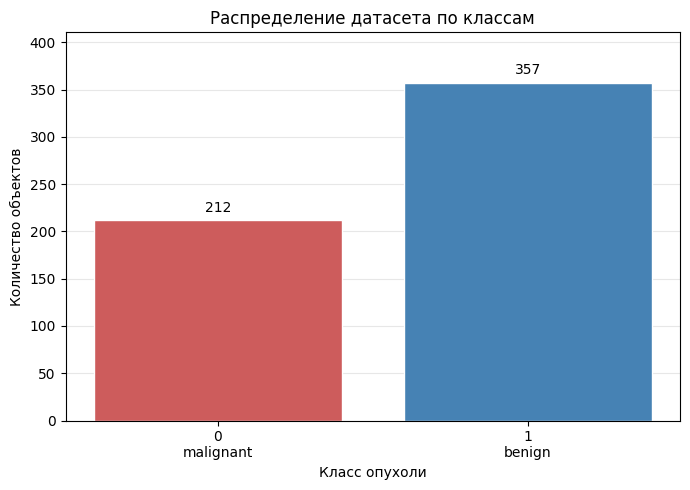

In [ ]:
print("Пропуски:", int(df.isna().sum().sum()))
print("Полные повторы:", int(df.duplicated().sum()))

class_names = {0: "malignant (злокачественная)", 1: "benign (доброкачественная)"}
class_counts = df["target"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Класс": [class_names[i] for i in class_counts.index],
    "Количество": class_counts.values,
    "Доля, %": (class_counts.values / len(df) * 100).round(2)
}, index=class_counts.index)
class_distribution.index.name = "target"

display(class_distribution)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["0\nmalignant", "1\nbenign"],
    class_counts.values,
    color=["indianred", "steelblue"],
    edgecolor="white"
)

# Подписываем количество объектов над каждым столбцом
ax.bar_label(bars, padding=4)

ax.set_xlabel("Класс опухоли")
ax.set_ylabel("Количество объектов")
ax.set_title("Распределение датасета по классам")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Пропусков и повторов нет. Классы распределены неравномерно: доброкачественных
образцов примерно в 1,7 раза больше, чем злокачественных. Дисбаланс умеренный,
но его нужно учитывать при оценке модели.

## Разделение данных

Данные делятся на три части в соотношении 60 / 20 / 20:

- **обучающая** выборка — на ней подбираются веса сети;
- **проверочная (validation)** — на ней после каждой эпохи отслеживается качество
  и выбирается лучшая эпоха;
- **тестовая** — используется один раз в конце для итоговой оценки.

Параметр `stratify` сохраняет одинаковое соотношение классов во всех частях.
`random_state` фиксирует случайное разбиение.

In [ ]:
X_all = df.drop(columns="target").to_numpy(dtype=np.float32)
y_all = df["target"].to_numpy(dtype=np.float32)

# Сначала отделяем тест (20%), затем из остатка проверочную часть (25% от 80% = 20%)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=42
)

split_info = pd.DataFrame({
    "Объектов": [len(y_tr), len(y_val), len(y_te)],
    "Доля класса 1, %": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]
}, index=["train", "val", "test"])

display(split_info)

,Объектов,"Доля класса 1, %"
train,341,62.7566
val,114,62.2807
test,114,63.1579


## Стандартизация признаков

Признаки имеют разные масштабы: например, площадь ядра измеряется сотнями единиц,
а гладкость — сотыми. Если подать такие данные в сеть без масштабирования,
признаки с большими числами будут доминировать, а обучение станет медленным и неустойчивым.

Каждый признак приводится к нулевому среднему и единичному разбросу:

$$
z_j=\frac{x_j-\mu_j}{\sigma_j},
$$

где $\mu_j$ и $\sigma_j$ — среднее и стандартное отклонение признака **в обучающей выборке**.
К проверочной и тестовой частям применяются те же значения $\mu_j$ и $\sigma_j$,
иначе информация о тесте «просочится» в обучение.

После этого массивы преобразуются в тензоры PyTorch, а метки — в столбец формы $(N,1)$,
как этого ожидают классы сети.

In [ ]:
# Масштабы исходных признаков (для наглядности: первые 8)
display(df.drop(columns="target").describe().T[["mean", "std", "min", "max"]].head(8))

mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)
X_tr, X_val, X_te = [(a - mean) / std for a in (X_tr, X_val, X_te)]

X_tr, X_val, X_te = [torch.from_numpy(a).float() for a in (X_tr, X_val, X_te)]
y_tr, y_val, y_te = [torch.from_numpy(a).float().view(-1, 1) for a in (y_tr, y_val, y_te)]

print("train:", X_tr.shape, "| val:", X_val.shape, "| test:", X_te.shape)
print("Среднее train после стандартизации (первые 3 признака):", X_tr.mean(dim=0)[:3].numpy().round(4))
print("Std train после стандартизации (первые 3 признака):", X_tr.std(dim=0)[:3].numpy().round(4))

,mean,std,min,max
mean radius,14.1273,3.5240,6.9810,28.1100
mean texture,19.2896,4.3010,9.7100,39.2800
mean perimeter,91.9690,24.2990,43.7900,188.5000
mean area,654.8891,351.9141,143.5000,2501.0000
mean smoothness,0.0964,0.0141,0.0526,0.1634
mean compactness,0.1043,0.0528,0.0194,0.3454
mean concavity,0.0888,0.0797,0.0000,0.4268
mean concave points,0.0489,0.0388,0.0000,0.2012


train: torch.Size([341, 30]) | val: torch.Size([114, 30]) | test: torch.Size([114, 30])
Среднее train после стандартизации (первые 3 признака): [ 0. -0.  0.]
Std train после стандартизации (первые 3 признака): [1.0015 1.0015 1.0015]


## Реализация нейронной сети

Классы `Dense`, `Activation_ReLU` и базовый класс `Loss` взяты из лекционной части выше.
Добавлены:

- `DenseHe` — слой `Dense` с He-инициализацией: веса берутся из нормального распределения
  с дисперсией $2/n_{in}$. При обычной инициализации `randn` на 30 входах значения на выходе слоя
  получаются слишком большими, и обучение идёт хуже;
- `Activation_Sigmoid` — сигмоида для выходного нейрона;
- `BinaryCrossentropyLoss` — бинарная кросс-энтропия. Вероятности ограничиваются
  интервалом $[\varepsilon,\,1-\varepsilon]$, чтобы не вычислять $\ln 0$.

Каждый класс имеет метод `forward` (прямой проход, сохраняет нужные для производной
величины) и `backward` (обратный проход, записывает градиент в `dinputs`).
Класс `Network` последовательно вызывает `forward` слоёв, а `backward` — в обратном порядке.

In [ ]:
class DenseHe(Dense):
    def __init__(self, n_inputs, n_neurons):
        super().__init__(n_inputs, n_neurons)
        self.weights = torch.randn(n_inputs, n_neurons) * (2.0 / n_inputs) ** 0.5


class Activation_Sigmoid:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = 1 / (1 + torch.exp(-inputs))
        return self.output

    def backward(self, dvalues):
        with torch.no_grad():
            self.dinputs = dvalues * self.output * (1 - self.output)


class BinaryCrossentropyLoss(Loss):
    eps = 1e-7

    def forward(self, y_pred, y_true):
        p = y_pred.clamp(self.eps, 1 - self.eps)
        sample_losses = -(y_true * torch.log(p) + (1 - y_true) * torch.log(1 - p))
        return sample_losses.mean(dim=1)          # потери по объектам, форма (N,)

    def backward(self, y_pred, y_true):
        with torch.no_grad():
            p = y_pred.clamp(self.eps, 1 - self.eps)
            self.dinputs = -(y_true / p - (1 - y_true) / (1 - p)) / len(y_pred)

In [ ]:
class Network:
    def __init__(self, layers):
        self.layers = layers
        self.dense_layers = [layer for layer in layers if isinstance(layer, Dense)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, dvalues):
        for layer in reversed(self.layers):
            layer.backward(dvalues)
            dvalues = layer.dinputs


def make_model():
    return Network([
        DenseHe(30, 16), Activation_ReLU(),
        DenseHe(16, 8),  Activation_ReLU(),
        DenseHe(8, 1),   Activation_Sigmoid(),
    ])


model = make_model()
loss_fn = BinaryCrossentropyLoss()

n_params = sum(layer.weights.numel() + layer.biases.numel() for layer in model.dense_layers)
print("Число обучаемых параметров:", n_params)

Число обучаемых параметров: 641


## Проверка градиентов

Прежде чем обучать сеть, проверим, что ручной обратный проход считает градиенты верно.
Для этого те же параметры и тот же мини-батч пропускаются через стандартные функции PyTorch
с автоматическим дифференцированием (`torch.autograd`), а затем градиенты сравниваются.

Разница порядка $10^{-7}$–$10^{-6}$ — это обычная погрешность вычислений в `float32`.
Если разница заметно больше, в формулах обратного прохода есть ошибка.

In [ ]:
xb, yb = X_tr[:32], y_tr[:32]

# Ручной прямой и обратный проход
out = model.forward(xb)
loss_fn.backward(out, yb)
model.backward(loss_fn.dinputs)

# То же самое на autograd, с копиями параметров
ws = [layer.weights.clone().requires_grad_(True) for layer in model.dense_layers]
bs = [layer.biases.clone().requires_grad_(True) for layer in model.dense_layers]

h = torch.relu(xb @ ws[0] + bs[0])
h = torch.relu(h @ ws[1] + bs[1])
p = torch.sigmoid(h @ ws[2] + bs[2])

loss_autograd = torch.nn.functional.binary_cross_entropy(p, yb)
loss_autograd.backward()

for i, layer in enumerate(model.dense_layers):
    diff_w = (layer.dweights - ws[i].grad).abs().max().item()
    diff_b = (layer.dbiases - bs[i].grad).abs().max().item()
    print(f"Слой {i + 1}: max|dW ручной - dW autograd| = {diff_w:.2e}, max|db ручной - db autograd| = {diff_b:.2e}")

Слой 1: max|dW ручной - dW autograd| = 1.49e-08, max|db ручной - db autograd| = 5.59e-09
Слой 2: max|dW ручной - dW autograd| = 1.49e-08, max|db ручной - db autograd| = 9.31e-09
Слой 3: max|dW ручной - dW autograd| = 2.98e-08, max|db ручной - db autograd| = 7.45e-09


## Обучение мини-батчевым градиентным спуском

На каждой эпохе обучающая выборка перемешивается и делится на мини-батчи по 32 объекта.
Для каждого мини-батча выполняются:

1. прямой проход — вычисление вероятностей $p$;
2. вычисление градиента ошибки по выходу сети;
3. обратный проход — градиенты по всем весам и смещениям;
4. шаг SGD: $w := w-\eta\,dw$, $b := b-\eta\,db$.

После каждой эпохи на обучающей и проверочной выборках считаются ошибка и AUC ROC.
Тестовая выборка в обучении не участвует.

Если ошибка на проверочной выборке перестаёт падать, а на обучающей продолжает снижаться,
сеть начинает **переобучаться**: запоминать обучающие примеры вместо выявления закономерностей.
Поэтому запоминаются веса эпохи с минимальной проверочной ошибкой и в конце восстанавливаются.

Для расчёта AUC ROC используется функция `auc_pairs` — доля пар «объект класса 1 — объект класса 0»,
в которых объект класса 1 получил оценку выше. Подробнее о ней — в разделе про AUC ROC.

In [ ]:
def predict_proba(model, X):
    return model.forward(X).view(-1)


def auc_pairs(y_true, scores):
    # AUC ROC как доля верно упорядоченных пар (класс 1, класс 0); ничья считается за 0.5
    y_true = y_true.view(-1)
    pos, neg = scores[y_true == 1], scores[y_true == 0]
    diff = pos.view(-1, 1) - neg.view(1, -1)
    return ((diff > 0).float() + 0.5 * (diff == 0).float()).mean().item()


n_epochs = 50
batch_size = 32
learning_rate = 0.1

model = make_model()
history = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": []}
best_val_loss, best_epoch, best_state = float("inf"), -1, None

start_time = time.perf_counter()

for epoch in range(n_epochs):
    perm = torch.randperm(len(X_tr))

    for i in range(0, len(X_tr), batch_size):
        idx = perm[i:i + batch_size]
        xb, yb = X_tr[idx], y_tr[idx]

        out = model.forward(xb)                 # прямой проход
        loss_fn.backward(out, yb)               # градиент по выходу сети
        model.backward(loss_fn.dinputs)         # обратный проход

        for layer in model.dense_layers:        # шаг SGD
            layer.weights -= learning_rate * layer.dweights
            layer.biases -= learning_rate * layer.dbiases

    p_tr, p_val = predict_proba(model, X_tr), predict_proba(model, X_val)
    history["train_loss"].append(loss_fn.calculate(p_tr.view(-1, 1), y_tr).item())
    history["val_loss"].append(loss_fn.calculate(p_val.view(-1, 1), y_val).item())
    history["train_auc"].append(auc_pairs(y_tr, p_tr))
    history["val_auc"].append(auc_pairs(y_val, p_val))

    # Запоминаем веса лучшей по проверочной ошибке эпохи
    if history["val_loss"][-1] < best_val_loss:
        best_val_loss, best_epoch = history["val_loss"][-1], epoch
        best_state = [(layer.weights.clone(), layer.biases.clone()) for layer in model.dense_layers]

    if epoch % 5 == 0 or epoch == n_epochs - 1:
        print(
            f"epoch {epoch:3d} | loss train {history['train_loss'][-1]:.4f} val {history['val_loss'][-1]:.4f}"
            f" | AUC train {history['train_auc'][-1]:.4f} val {history['val_auc'][-1]:.4f}"
        )

time_train = time.perf_counter() - start_time

# Возвращаем веса лучшей эпохи
for layer, (w, b) in zip(model.dense_layers, best_state):
    layer.weights, layer.biases = w, b

print(f"\nВремя обучения: {time_train:.2f} секунд")
print(f"Лучшая эпоха по проверочной ошибке: {best_epoch + 1} из {n_epochs} (val loss = {best_val_loss:.4f})")

epoch   0 | loss train 0.3249 val 0.3258 | AUC train 0.9718 val 0.9758
epoch   5 | loss train 0.0988 val 0.1128 | AUC train 0.9929 val 0.9934
epoch  10 | loss train 0.0668 val 0.0824 | AUC train 0.9965 val 0.9961
epoch  15 | loss train 0.0512 val 0.0711 | AUC train 0.9980 val 0.9961
epoch  20 | loss train 0.0421 val 0.0672 | AUC train 0.9990 val 0.9964
epoch  25 | loss train 0.0357 val 0.0646 | AUC train 0.9994 val 0.9971
epoch  30 | loss train 0.0307 val 0.0619 | AUC train 0.9996 val 0.9971
epoch  35 | loss train 0.0268 val 0.0606 | AUC train 0.9998 val 0.9971
epoch  40 | loss train 0.0231 val 0.0601 | AUC train 0.9999 val 0.9967
epoch  45 | loss train 0.0199 val 0.0596 | AUC train 0.9999 val 0.9971
epoch  49 | loss train 0.0176 val 0.0604 | AUC train 0.9999 val 0.9971

Время обучения: 0.77 секунд
Лучшая эпоха по проверочной ошибке: 45 из 50 (val loss = 0.0594)


## Зависимость ошибки и AUC от эпохи

На графиках сравниваются результаты на обучающей и проверочной выборках.

Левый график — бинарная кросс-энтропия: чем она ниже, тем точнее вероятности.
Правый — AUC ROC: чем ближе к 1, тем лучше модель отделяет классы.
Оранжевая пунктирная линия отмечает эпоху, веса которой оставлены для итоговой модели.

Растущий разрыв между кривыми, особенно рост проверочной ошибки при падении обучающей,
показывает, что результат на обучении плохо переносится на новые данные.

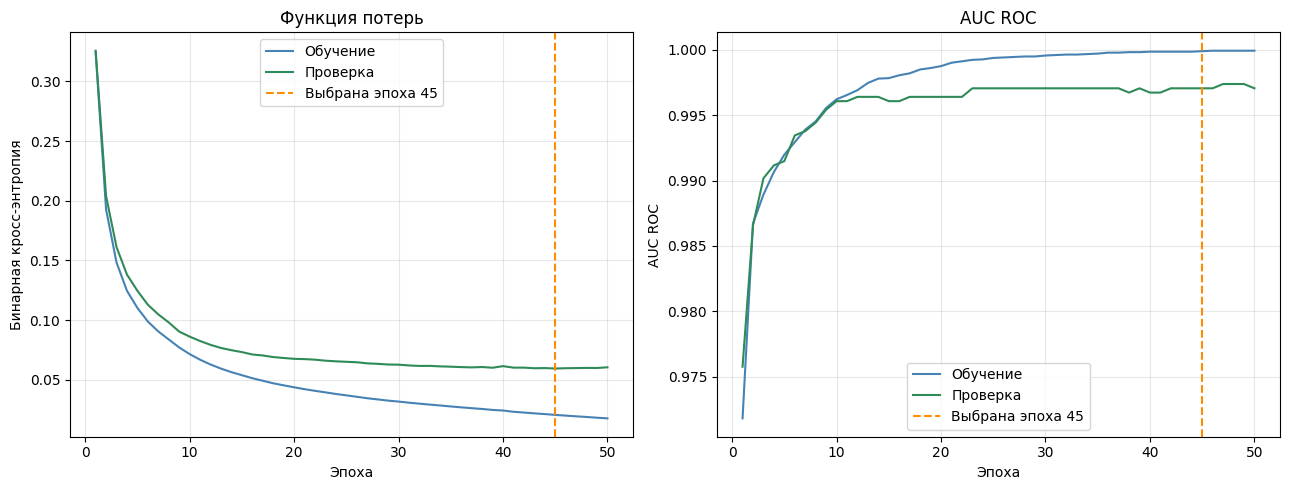

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
epochs = np.arange(1, n_epochs + 1)

axs[0].plot(epochs, history["train_loss"], label="Обучение", color="steelblue")
axs[0].plot(epochs, history["val_loss"], label="Проверка", color="seagreen")
axs[0].axvline(best_epoch + 1, color="darkorange", linestyle="--", label=f"Выбрана эпоха {best_epoch + 1}")
axs[0].set_xlabel("Эпоха")
axs[0].set_ylabel("Бинарная кросс-энтропия")
axs[0].set_title("Функция потерь")
axs[0].grid(alpha=0.3)
axs[0].legend()

axs[1].plot(epochs, history["train_auc"], label="Обучение", color="steelblue")
axs[1].plot(epochs, history["val_auc"], label="Проверка", color="seagreen")
axs[1].axvline(best_epoch + 1, color="darkorange", linestyle="--", label=f"Выбрана эпоха {best_epoch + 1}")
axs[1].set_xlabel("Эпоха")
axs[1].set_ylabel("AUC ROC")
axs[1].set_title("AUC ROC")
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

## Как рассчитываются метрики

В задаче два класса. За положительный принимается класс `1` (доброкачественная опухоль).
По результатам классификации определяются:

- TP — объекты класса `1`, распознанные правильно;
- TN — объекты класса `0`, распознанные правильно;
- FP — объекты класса `0`, ошибочно отнесённые к классу `1`;
- FN — объекты класса `1`, ошибочно отнесённые к классу `0`.

Вероятность $p$ переводится в ответ по порогу: если $p\ge0{,}5$, то предсказывается класс `1`.

**Accuracy** — доля правильных ответов:

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}.
$$

**Precision** — какая доля ответов «класс 1» правильная:

$$
Precision=\frac{TP}{TP+FP}.
$$

**Recall** — какую долю настоящих объектов класса `1` удалось найти:

$$
Recall=\frac{TP}{TP+FN}.
$$

**F1-score** — гармоническое среднее precision и recall:

$$
F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}.
$$

Все эти метрики зависят от выбранного порога. **AUC ROC** от порога не зависит:
он оценивает только то, насколько правильно модель упорядочивает объекты по оценке.

Для медицинской задачи особенно важна доля злокачественных опухолей, ошибочно
принятых за доброкачественные. Это объекты класса `0` с ответом `1`, то есть FP в нашей матрице.
Поэтому далее отдельно приводятся метрики обоих классов.

In [ ]:
def evaluate(X, y, name):
    p = predict_proba(model, X)
    y_np, p_np = y.view(-1).numpy(), p.numpy()
    pred = (p_np >= 0.5).astype(int)
    return {
        "Выборка": name,
        "Loss (BCE)": loss_fn.calculate(p.view(-1, 1), y).item(),
        "Accuracy": accuracy_score(y_np, pred),
        "Precision": precision_score(y_np, pred, zero_division=0),
        "Recall": recall_score(y_np, pred, zero_division=0),
        "F1-score": f1_score(y_np, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_np, p_np)
    }


metrics_table = pd.DataFrame([
    evaluate(X_tr, y_tr, "train"),
    evaluate(X_val, y_val, "val"),
    evaluate(X_te, y_te, "test")
]).set_index("Выборка")

display(metrics_table)

# Подробный отчёт по каждому классу на тестовой выборке
p_te = predict_proba(model, X_te)
y_te_np = y_te.view(-1).numpy()
pred_te = (p_te.numpy() >= 0.5).astype(int)

print("Отчёт по классам (тестовая выборка, порог 0.5):")
print(classification_report(
    y_te_np,
    pred_te,
    labels=[0, 1],
    target_names=["malignant (0)", "benign (1)"],
    digits=3,
    zero_division=0
))

,Loss (BCE),Accuracy,Precision,Recall,F1-score,ROC-AUC
Выборка,,,,,,
train,0.0205,0.9912,0.9907,0.9953,0.9930,0.9999
val,0.0594,0.9825,0.9859,0.9859,0.9859,0.9971
test,0.0946,0.9561,0.9718,0.9583,0.9650,0.9934


Отчёт по классам (тестовая выборка, порог 0.5):
               precision    recall  f1-score   support

malignant (0)      0.930     0.952     0.941        42
   benign (1)      0.972     0.958     0.965        72

     accuracy                          0.956       114
    macro avg      0.951     0.955     0.953       114
 weighted avg      0.957     0.956     0.956       114



## Матрица ошибок

Строки матрицы соответствуют настоящим классам, столбцы — предсказанным.
На главной диагонали находятся правильные ответы, остальные ячейки — ошибки:
например, строка `malignant` и столбец `benign` показывают злокачественные опухоли,
которые модель приняла за доброкачественные.

Сумма главной диагонали, делённая на сумму всех элементов, равна accuracy.

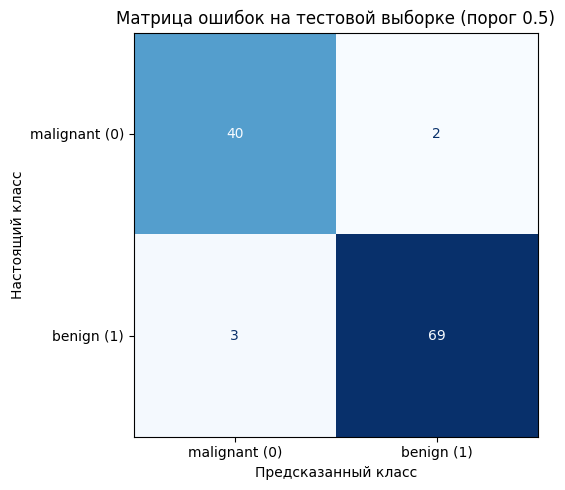

TN = 40, FP = 2, FN = 3, TP = 69
Accuracy по матрице: 109 / 114 = 95.61%
Злокачественных опухолей принято за доброкачественные: 2 из 42


In [ ]:
cm = confusion_matrix(y_te_np, pred_te, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["malignant (0)", "benign (1)"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Настоящий класс")
ax.set_title("Матрица ошибок на тестовой выборке (порог 0.5)")

plt.tight_layout()
plt.show()

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Accuracy по матрице: {tn + tp} / {cm.sum()} = {(tn + tp) / cm.sum():.2%}")
print(f"Злокачественных опухолей принято за доброкачественные: {fp} из {tn + fp}")

## ROC-кривая и AUC ROC

Материал основан на статье А. Дьяконова
[«AUC ROC (площадь под кривой ошибок)»](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/).

ROC-кривая показывает, как меняется соотношение правильно найденных объектов
и ложных срабатываний при изменении порога классификации.

По горизонтальной оси откладывается FPR — доля ложных срабатываний:

$$
FPR=\frac{FP}{FP+TN}.
$$

По вертикальной оси — TPR, доля правильно найденных объектов класса `1` (то же, что recall):

$$
TPR=\frac{TP}{TP+FN}.
$$

Каждый порог задаёт точку $(FPR, TPR)$. При снижении порога растут и TPR, и FPR.
Лучше, когда кривая проходит ближе к левому верхнему углу.

### Как строится кривая

Пусть в выборке $m$ объектов класса `1` и $n$ объектов класса `0`.

1. Объекты сортируются по убыванию оценки модели.
2. Квадрат $[0,1]^2$ разбивается сеткой на $m\times n$ клеток. Начинаем из точки $(0,0)$.
3. Для каждого объекта по порядку: если он класса `1`, делаем шаг **вверх** на $1/m$;
   если класса `0` — шаг **вправо** на $1/n$.
4. Если у нескольких объектов оценки одинаковы, шаг для всей группы делается сразу
   по диагонали, потому что порог не может разделить такие объекты.

### Что означает AUC

AUC ROC — площадь под этой кривой:

$$
AUC=\int_0^1 TPR(FPR)\,dFPR.
$$

Для построенной по данным кривой площадь считается суммированием площадей трапеций.

Смысл AUC: это **доля пар** (объект класса `1`, объект класса `0`), которые модель упорядочила
верно, то есть объекту класса `1` присвоила оценку выше. Это же вероятность того,
что случайно выбранный объект класса `1` получит оценку выше случайного объекта класса `0`.
Ничья считается за половину верно упорядоченной пары.

- AUC = 1: идеальное разделение классов;
- AUC около 0,5: уровень случайного ранжирования;
- AUC меньше 0,5: порядок оценок в целом противоположен правильному;
- $Gini=2\cdot AUC-1$.

Ниже кривая и площадь вычисляются вручную и сверяются с `sklearn.metrics.roc_auc_score`.

In [ ]:
def roc_curve_manual(y_true, scores):
    y_true = y_true.view(-1)
    order = torch.argsort(scores, descending=True)      # сортировка по убыванию оценки
    y_sorted, s_sorted = y_true[order], scores[order]

    tps = torch.cumsum(y_sorted, dim=0)                 # сколько единиц просмотрено (шаги вверх)
    fps = torch.cumsum(1 - y_sorted, dim=0)             # сколько нулей просмотрено (шаги вправо)
    m, n = tps[-1], fps[-1]

    # Конец каждой группы одинаковых оценок: внутри группы шаг делается сразу целиком
    last_in_group = torch.where(s_sorted[1:] != s_sorted[:-1])[0]
    idx = torch.cat([last_in_group, torch.tensor([len(s_sorted) - 1])])

    zero = torch.zeros(1)
    fpr = torch.cat([zero, fps[idx] / n])
    tpr = torch.cat([zero, tps[idx] / m])
    thresholds = s_sorted[idx]
    return fpr, tpr, thresholds


def auc_trapz(fpr, tpr):
    # Площадь под кривой методом трапеций
    return torch.trapz(tpr, fpr).item()

In [ ]:
fpr, tpr, thr = roc_curve_manual(y_te, p_te)

auc_roc = auc_trapz(fpr, tpr)
auc_pair = auc_pairs(y_te, p_te)
auc_sk = roc_auc_score(y_te_np, p_te.numpy())

auc_table = pd.DataFrame({
    "Способ расчёта": [
        "Площадь под кривой (трапеции)",
        "Доля верно упорядоченных пар",
        "sklearn.metrics.roc_auc_score"
    ],
    "AUC ROC": [auc_roc, auc_pair, auc_sk]
}).set_index("Способ расчёта")

display(auc_table.round(5))
print(f"Gini = 2 * AUC - 1 = {2 * auc_roc - 1:.5f}")

,AUC ROC
Способ расчёта,
Площадь под кривой (трапеции),0.9934
Доля верно упорядоченных пар,0.9934
sklearn.metrics.roc_auc_score,0.9934


Gini = 2 * AUC - 1 = 0.98677


### ROC-кривая и распределение оценок

На левом графике показана ROC-кривая модели и диагональ — ориентир случайного ранжирования.
Красная точка отмечает положение порога 0,5.

На правом графике — гистограммы оценок сети отдельно для каждого класса.
Чем меньше гистограммы перекрываются, тем выше AUC: при полном разделении классов
любой объект класса `1` получает оценку выше любого объекта класса `0`.

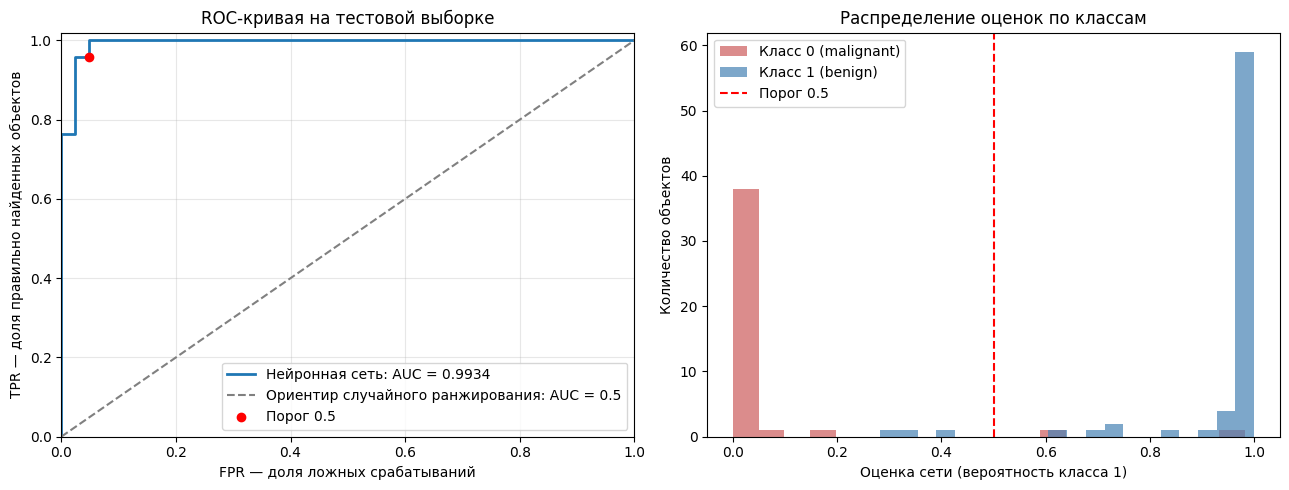

При пороге 0.5: TPR = 0.9583, FPR = 0.0476


In [ ]:
threshold = 0.5
tpr_t = tp / (tp + fn)
fpr_t = fp / (fp + tn)
yt = y_te.view(-1)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

axs[0].plot(fpr.numpy(), tpr.numpy(), linewidth=2, label=f"Нейронная сеть: AUC = {auc_roc:.4f}")
axs[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Ориентир случайного ранжирования: AUC = 0.5")
axs[0].scatter([fpr_t], [tpr_t], color="red", zorder=3, label=f"Порог {threshold}")
axs[0].set_xlabel("FPR — доля ложных срабатываний")
axs[0].set_ylabel("TPR — доля правильно найденных объектов")
axs[0].set_title("ROC-кривая на тестовой выборке")
axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1.02)
axs[0].grid(alpha=0.3)
axs[0].legend(loc="lower right")

axs[1].hist(p_te[yt == 0].numpy(), bins=20, alpha=0.7, color="indianred", label="Класс 0 (malignant)")
axs[1].hist(p_te[yt == 1].numpy(), bins=20, alpha=0.7, color="steelblue", label="Класс 1 (benign)")
axs[1].axvline(threshold, color="red", linestyle="--", label=f"Порог {threshold}")
axs[1].set_xlabel("Оценка сети (вероятность класса 1)")
axs[1].set_ylabel("Количество объектов")
axs[1].set_title("Распределение оценок по классам")
axs[1].legend()

plt.tight_layout()
plt.show()

print(f"При пороге {threshold}: TPR = {tpr_t:.4f}, FPR = {fpr_t:.4f}")

### Выбор порога классификации

Выбор порога — это выбор точки на ROC-кривой. Чем ниже порог, тем больше объектов
относится к классу `1`: растёт и TPR, и FPR.

Для медицинской задачи пропуск злокачественной опухоли обычно опаснее, чем лишнее
дополнительное обследование. Поэтому порог выбирают исходя из цены ошибок, а не
автоматически равным 0,5. Таблица показывает, как меняются показатели при разных порогах.

In [ ]:
rows = []
for t_ in [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]:
    pr = (p_te >= t_).float()
    tp_ = ((pr == 1) & (yt == 1)).sum().item()
    fn_ = ((pr == 0) & (yt == 1)).sum().item()
    fp_ = ((pr == 1) & (yt == 0)).sum().item()
    tn_ = ((pr == 0) & (yt == 0)).sum().item()
    rows.append({
        "Порог": t_,
        "TPR": tp_ / (tp_ + fn_),
        "FPR": fp_ / (fp_ + tn_),
        "Злокачественных принято за доброкачественные": fp_,
        "Доброкачественных принято за злокачественные": fn_
    })

display(pd.DataFrame(rows).set_index("Порог"))

,TPR,FPR,Злокачественных принято за доброкачественные,Доброкачественных принято за злокачественные
Порог,,,,
0.0500,1.0000,0.0952,4,0
0.1000,1.0000,0.0714,3,0
0.2500,1.0000,0.0476,2,0
0.5000,0.9583,0.0476,2,3
0.7500,0.9028,0.0238,1,7
0.9000,0.8750,0.0238,1,9
0.9500,0.8333,0.0238,1,12


## Свойства AUC ROC

Проверим на практике несколько утверждений из статьи.

1. **Идеальный, случайный и наихудший алгоритм.** Если все объекты класса `1` получают оценки выше
   всех объектов класса `0`, AUC = 1. При случайных оценках AUC около 0,5. Если порядок
   полностью обратный, AUC = 0.
2. **AUC зависит только от порядка оценок, а не от их значений.** Любое строго возрастающее
   преобразование оценок (возведение в куб, линейное преобразование) не меняет AUC.
3. **AUC для бинарных ответов.** Если модель выдаёт не оценки, а только ответы 0 и 1,
   ROC-кривая состоит из трёх точек: $(0,0)$, $(FPR,TPR)$ и $(1,1)$.
   Площадь под ней равна
   $$
   AUC=\frac{1+TPR-FPR}{2}=\frac{TPR+TNR}{2},
   $$
   то есть среднему recall по двум классам (balanced accuracy).
   Бинаризация оценок теряет информацию, поэтому AUC при этом обычно уменьшается.

In [ ]:
# 1) Идеальный, случайный и наихудший порядок оценок
y_demo = torch.cat([torch.ones(50), torch.zeros(50)])
perfect = torch.cat([torch.rand(50) * 0.5 + 0.5, torch.rand(50) * 0.5])    # единицы выше нулей
worst = 1 - perfect
random_scores = torch.rand(100)

demo_rows = []
for name, s in [("Идеальный порядок", perfect), ("Случайные оценки", random_scores), ("Обратный порядок", worst)]:
    f_, t_, _ = roc_curve_manual(y_demo, s)
    demo_rows.append({"Оценки": name, "AUC ROC": auc_trapz(f_, t_)})

display(pd.DataFrame(demo_rows).set_index("Оценки").round(3))

,AUC ROC
Оценки,
Идеальный порядок,1.0000
Случайные оценки,0.4140
Обратный порядок,0.0000


In [ ]:
# 2) Строго возрастающее преобразование оценок не меняет AUC
transform_rows = [
    {"Оценки": "p", "AUC ROC": auc_pairs(y_te, p_te)},
    {"Оценки": "p ** 3", "AUC ROC": auc_pairs(y_te, p_te ** 3)},
    {"Оценки": "10 * p - 3", "AUC ROC": auc_pairs(y_te, 10 * p_te - 3)},
]
display(pd.DataFrame(transform_rows).set_index("Оценки").round(5))

# 3) AUC бинарных ответов: (1 + TPR - FPR) / 2
bin_pred = (p_te >= 0.5).float()
print(f"AUC бинарных ответов (по парам): {auc_pairs(y_te, bin_pred):.5f}")
print(f"(1 + TPR - FPR) / 2            : {(1 + tpr_t - fpr_t) / 2:.5f}")
print(f"AUC по вероятностям (для сравнения): {auc_roc:.5f}")

,AUC ROC
Оценки,
p,0.9934
p ** 3,0.9934
10 * p - 3,0.9934


AUC бинарных ответов (по парам): 0.95536
(1 + TPR - FPR) / 2            : 0.95536
AUC по вероятностям (для сравнения): 0.99339


## Разброс AUC на небольшой выборке

В статье отмечается, что на выборках из нескольких сотен объектов оценка AUC
получается неточной. В нашем тесте всего 114 объектов, поэтому значение AUC
зависит от того, какие именно образцы в него попали.

Оценим разброс методом **бутстрепа**: из тестовой выборки 1000 раз случайно выбирается
столько же объектов с возвращением, и для каждой такой выборки считается AUC.
Диапазон, в который попадают 95% значений, даёт представление о точности оценки.
Это не доверительный интервал для будущих данных, а оценка устойчивости именно на этом тесте.

AUC на тесте = 0.9934
95% бутстреп-диапазон: [0.9794, 1.0000]


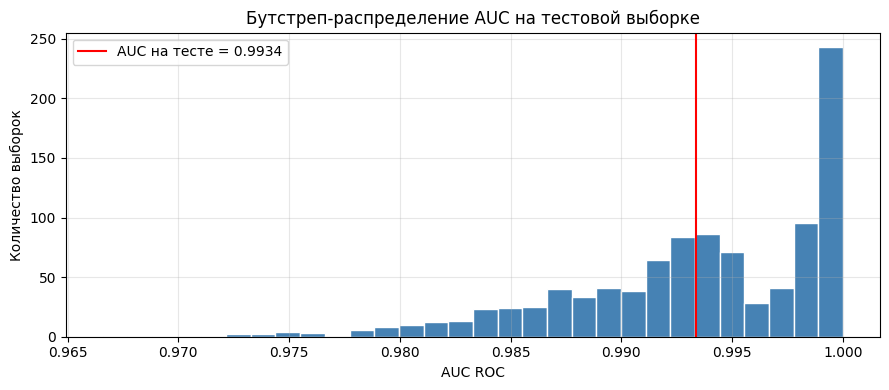

In [ ]:
g = torch.Generator().manual_seed(0)
boot_aucs = []

for _ in range(1000):
    idx = torch.randint(0, len(p_te), (len(p_te),), generator=g)
    # ROC не определена, если в выборке остался только один класс
    if yt[idx].sum() in (0, len(idx)):
        continue
    boot_aucs.append(auc_pairs(yt[idx], p_te[idx]))

boot_aucs = torch.tensor(boot_aucs)
auc_low, auc_high = torch.quantile(boot_aucs, torch.tensor([0.025, 0.975])).tolist()

print(f"AUC на тесте = {auc_roc:.4f}")
print(f"95% бутстреп-диапазон: [{auc_low:.4f}, {auc_high:.4f}]")

plt.figure(figsize=(9, 4))
plt.hist(boot_aucs.numpy(), bins=30, color="steelblue", edgecolor="white")
plt.axvline(auc_roc, color="red", label=f"AUC на тесте = {auc_roc:.4f}")
plt.xlabel("AUC ROC")
plt.ylabel("Количество выборок")
plt.title("Бутстреп-распределение AUC на тестовой выборке")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Итоговые результаты

Сводка по обученной модели на тестовой выборке. Числа считаются автоматически
по результатам запуска.

In [ ]:
test_metrics = metrics_table.loc["test"]

print("Архитектура: 30 -> 16 -> 8 -> 1 (ReLU, ReLU, сигмоида)")
print(f"Параметров: {n_params} | эпох: {n_epochs} | batch: {batch_size} | lr: {learning_rate}")
print(f"Лучшая эпоха по val loss: {best_epoch + 1} | время обучения: {time_train:.2f} сек.")
print()
print(f"Test accuracy : {test_metrics['Accuracy']:.2%}")
print(f"Test F1-score : {test_metrics['F1-score']:.4f}")
print(f"Test ROC-AUC  : {test_metrics['ROC-AUC']:.4f} (95% бутстреп-диапазон [{auc_low:.4f}, {auc_high:.4f}])")
print(f"Recall по классу 0 (malignant): {tn / (tn + fp):.2%}")
print(f"Recall по классу 1 (benign)   : {tp / (tp + fn):.2%}")

Архитектура: 30 -> 16 -> 8 -> 1 (ReLU, ReLU, сигмоида)
Параметров: 641 | эпох: 50 | batch: 32 | lr: 0.1
Лучшая эпоха по val loss: 45 | время обучения: 0.77 сек.

Test accuracy : 95.61%
Test F1-score : 0.9650
Test ROC-AUC  : 0.9934 (95% бутстреп-диапазон [0.9794, 1.0000])
Recall по классу 0 (malignant): 95.24%
Recall по классу 1 (benign)   : 95.83%


## Интерпретация полученных результатов

**Качество модели.** Нейронная сеть с двумя скрытыми слоями хорошо разделяет классы на этом
наборе: значения AUC ROC на проверочной и тестовой выборках близки к единице,
а accuracy существенно выше доли самого частого класса (около 63%).
Точные числа приведены в таблицах выше и могут немного отличаться между запусками
из-за случайной инициализации весов и перемешивания мини-батчей.

**Поведение при обучении.** Ошибка на обучающей выборке монотонно снижается. Проверочная ошибка
сначала падает, а затем перестаёт улучшаться или медленно растёт — это признак начала переобучения.
Из-за этого для итоговой модели выбраны веса эпохи с минимальной проверочной ошибкой.

**ROC-кривая и AUC.** AUC ROC, посчитанный тремя способами (площадь под кривой, доля верно
упорядоченных пар, `scikit-learn`), даёт одно и то же значение. Это подтверждает связь,
описанную в статье: площадь под ROC-кривой совпадает с долей правильно упорядоченных пар.

**Порог.** Метрики accuracy, precision, recall и F1 зависят от порога, а AUC — нет.
Для медицинской задачи порог 0,5 не обязан быть оптимальным: снижая или повышая его,
можно уменьшить число пропущенных злокачественных опухолей ценой большего числа
ложных тревог. Конкретное значение порога следует выбирать по цене ошибок.

**Надёжность оценки.** Тестовая выборка небольшая (114 объектов), поэтому AUC имеет
заметный разброс. Бутстреп-диапазон показывает, что различия в третьем знаке
после запятой не стоит считать значимыми.

## Вывод

В работе реализована и обучена полносвязная нейронная сеть `30 → 16 → 8 → 1`
для бинарной классификации опухолей на наборе «Breast Cancer Wisconsin».
Прямой и обратный проходы написаны вручную на тензорах PyTorch, а корректность
градиентов подтверждена сравнением с `torch.autograd`.

Сеть обучалась мини-батчевым стохастическим градиентным спуском с функцией потерь
бинарной кросс-энтропии. Для защиты от переобучения использовалась проверочная
выборка: итоговая модель получена из эпохи с минимальной проверочной ошибкой.

Качество оценено по accuracy, precision, recall, F1-score, матрице ошибок и AUC ROC.
ROC-кривая и AUC реализованы «с нуля» по алгоритму из статьи А. Дьяконова и совпали
с `sklearn.metrics.roc_auc_score`.

AUC ROC не зависит от порога и от монотонных преобразований оценок и характеризует
качество ранжирования объектов моделью. Остальные метрики зависят от порога, который
в прикладной задаче нужно выбирать по цене ошибок. Бутстреп показал, что на небольшой
тестовой выборке AUC определяется с заметной погрешностью.